# Food Access Visualizations
Version 1

**Team: Trace Analysts**

This notebook produces the figures for the analysis. It reads the scored output of the pipeline (`outputs/cook_county_scored.csv`) and generates reviewer-ready charts.

> **Data note:** LRAM is *historical* — 2010 boundaries & population, 2014-18 ACS,
> 2019 retailers. These figures describe *areas* (census tracts), not individuals,
> and should not be read as a 2026 snapshot.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from pathlib import Path

In [2]:
# Set the path to the scored data created by the pipeline.
# CHANGE THIS PATH IF YOUR FILE IS STORED SOMEWHERE ELSE
SCORED_PATH = Path("outputs/cook_county_scored.csv")

# Set the path to the scored data created by the pipeline.
# CHANGE THESE TWO LINES IF YOUR DATA IS FOR ANOTHER AREA
STATE_NAME = "Illinois"
COUNTY_NAME = "Cook County"

# Combine the county and state names for chart titles.
AREA_LABEL = COUNTY_NAME, STATE_NAME

# Create a folder for saving the finished charts.
# The folder is created automatically if it does not exist.
FIG_DIR = Path("figures"); FIG_DIR.mkdir(exist_ok=True)

# List the six indicators used to calculate the food access priority score.
INDEX_VARS = [
    "PovertyRate",       # % population below federal poverty line
    "lapop1share",       # % of tract >1 mi from a supermarket
    "lalowi1share",      # % low-income AND >1 mi from a supermarket
    "lahunv1share",      # % housing units with no vehicle AND >1 mi
    "lasnap1share",      # % SNAP households AND >1 mi
    "MedianFamilyIncome" # Will invert: lower income = higher need
]

# Give the indicators shorter, easier-to-read names for the charts.
LABELS = {
    "PovertyRate":        "Poverty rate (%)",
    "lapop1share":        "% population >1 mi from supermarket",
    "lalowi1share":       "% low-income & >1 mi",
    "lahunv1share":       "% no-vehicle & >1 mi",
    "lasnap1share":       "% SNAP & >1 mi",
    "MedianFamilyIncome": "Median family income ($)",
    "PriorityScore":      "Priority score (0-1)"}

# Load the scored CSV file into a DataFrame.
df = pd.read_csv(SCORED_PATH)

# Format census tract IDs as 11-digit strings for consistent labeling.
df["CensusTract"] = df["CensusTract"].astype(str).str.split(".").str[0].str.zfill(11)


# Check loaded data
print(f"Loaded {len(df):,} tracts, {df.shape[1]} columns from {SCORED_PATH}")
print("PriorityScore range:", round(df.PriorityScore.min(), 3), "->", round(df.PriorityScore.max(), 3))

Loaded 1,314 tracts, 21 columns from outputs\cook_county_scored.csv
PriorityScore range: 0.003 -> 0.967


## Figure 1 — Distributions of the six index variables
Why: shows the shape and spread of each indicator and *why* min-max rescaling is needed (income spans tens of thousands; shares and poverty are 0-100). One subplot per variable.

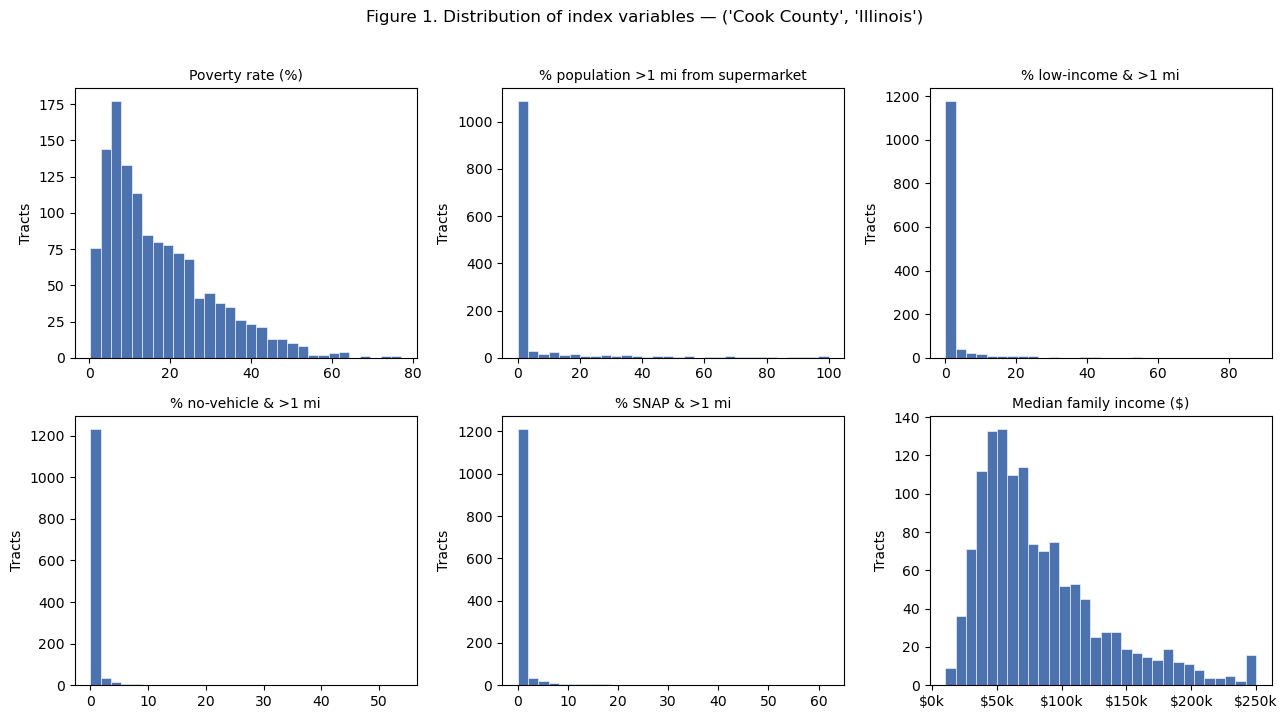

Summary (median / min / max):
  Poverty rate (%)                                 13.5        0.3       77.1
  % population >1 mi from supermarket               0.0        0.0      100.0
  % low-income & >1 mi                              0.0        0.0       87.7
  % no-vehicle & >1 mi                              0.0        0.0       53.9
  % SNAP & >1 mi                                    0.0        0.0       62.0
  Median family income ($)                      69436.0    10131.0   250001.0


In [3]:
# Create six plots arranged in two rows and three columns.
fig, axes = plt.subplots(2, 3, figsize=(13, 7))

# Create a histogram for each indicator to show how its values are distributed.
for ax, v in zip(axes.ravel(), INDEX_VARS):
    data = df[v].dropna()

     # Display the frequency of values using 30 bins.
    ax.hist(data, bins=30, color="#4C72B0", edgecolor="white", linewidth=0.4)

     # Add a readable title and label the vertical axis.
    ax.set_title(LABELS.get(v, v), fontsize=10)
    ax.set_ylabel("Tracts")

      # Display income values in thousands of dollars to make the axis easier to read.
    if v == "MedianFamilyIncome":
        ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"${x/1000:.0f}k"))

# Add an overall title and adjust spacing between the plots.
fig.suptitle(f"Figure 1. Distribution of index variables — {AREA_LABEL}", fontsize=12, y=1.02)
fig.tight_layout()

# Save the chart as a PNG file and display it.
fig.savefig(FIG_DIR / "fig1_distributions.png", bbox_inches="tight")
plt.show()

# Print the median, minimum, and maximum for each indicator.
print("Summary (median / min / max):")
for v in INDEX_VARS:
    s = df[v]
    print(f"  {LABELS.get(v,v):42s} {s.median():10.1f} {s.min():10.1f} {s.max():10.1f}")

## Figure 2 — The data-quality reality behind the distance shares
Why: ~74% of Cook County tracts had `"NULL"` distance shares that the pipeline treats as 0 (they are *not low-access at 1 mile*, i.e. a true zero — not missing data). This chart makes that visible so a reviewer doesn't mistake the zero spike in Figure 1 for an error.

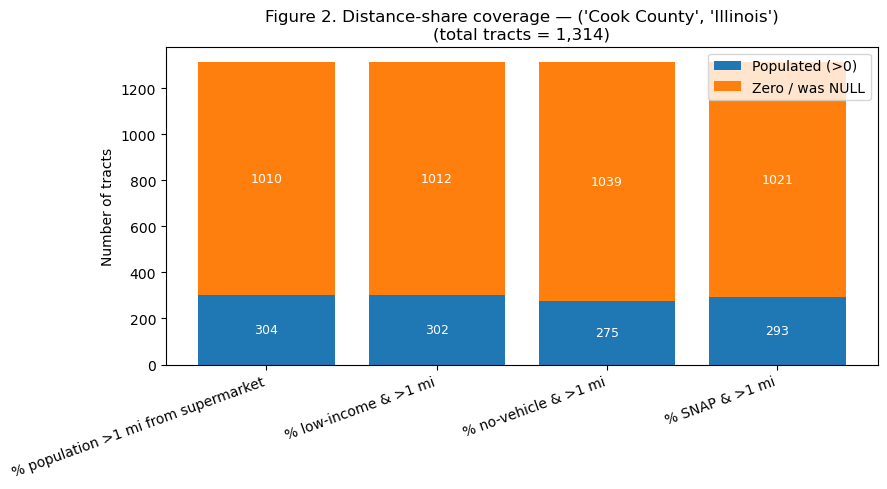

Example: lapop1share populated in 304 of 1314 tracts (23%); 1010 are zero/NULL (77%).


In [4]:
# Identify the four indicators that measure distance from supermarkets.
share_vars = ["lapop1share", "lalowi1share", "lahunv1share", "lasnap1share"]

# Count how many tracts have a value greater than zero for each indicator.
populated = [(df[v] > 0).sum() for v in share_vars]

# Count how many tracts have a value of zero for each indicator.
zerofill  = [(df[v] == 0).sum() for v in share_vars]

# Set the horizontal positions for the four indicators.
x = np.arange(len(share_vars))

# Create the chart.
fig, ax = plt.subplots(figsize=(9, 5))

# Show tracts with populated values as the bottom section of each bar.
ax.bar(x, populated, label="Populated (>0)")

# Stack the zero values above the populated values.
ax.bar(x, zerofill, bottom=populated, label="Zero / was NULL")

# Add indicator names and rotate them to improve readability.
ax.set_xticks(x); ax.set_xticklabels([LABELS[v] for v in share_vars], rotation=20, ha="right")

# Add the axis label, chart title, and legend.
ax.set_ylabel("Number of tracts")
ax.set_title(f"Figure 2. Distance-share coverage — {AREA_LABEL}\n(total tracts = {len(df):,})")
ax.legend()

# Add the number of tracts inside each section of the bars.
for i, (p, z) in enumerate(zip(populated, zerofill)):
    ax.text(i, p/2, str(p), ha="center", va="center", color="white", fontsize=9)
    ax.text(i, p + z/2, str(z), ha="center", va="center", color="white", fontsize=9)

# Adjust the layout, save the chart, and display it.
fig.tight_layout()
fig.savefig(FIG_DIR / "fig2_share_coverage.png", bbox_inches="tight")
plt.show()

# Print an example showing the number and percentage of populated and zero values.
print(f"Example: lapop1share populated in {populated[0]} of {len(df)} tracts "
      f"({populated[0]/len(df)*100:.0f}%); {zerofill[0]} are zero/NULL "
      f"({zerofill[0]/len(df)*100:.0f}%).")

## Figure 3 — Top-20 priority tracts
Why: the headline figure. It answers the research question — which tracts rank highest for food-access need. Horizontal bars, highest score on top.

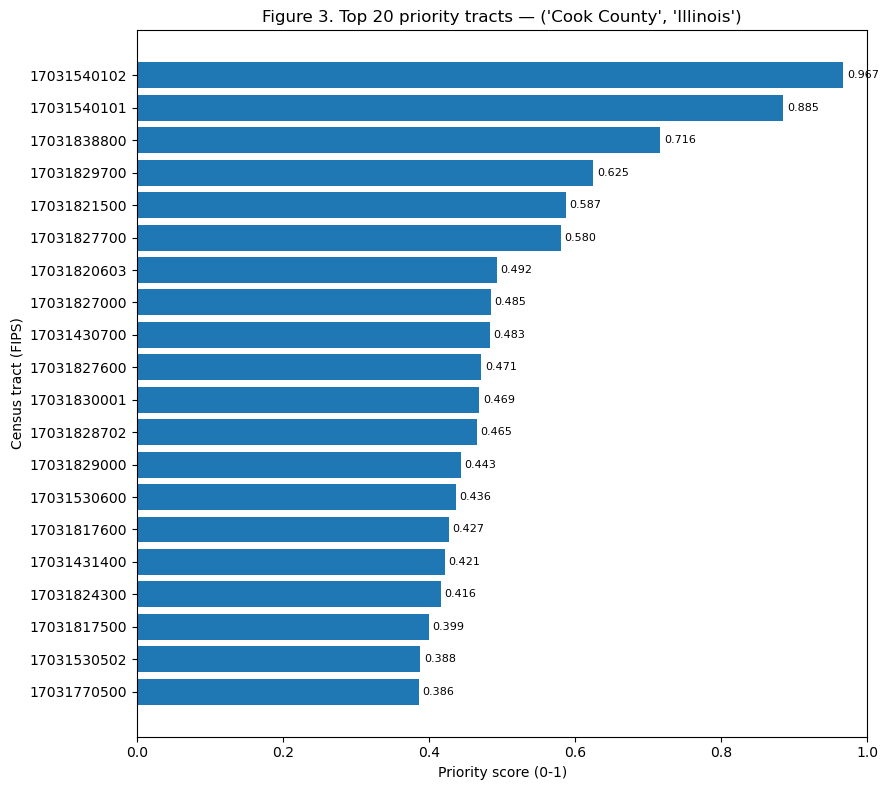

Highest-priority tract: 17031540102 | score 0.967


In [5]:
# Sort the tracts from highest to lowest priority score and select the top 20.
top20 = df.sort_values("PriorityScore", ascending=False).head(20)

# Create a horizontal bar chart showing the selected tracts.
fig, ax = plt.subplots(figsize=(9, 8))
ax.barh(top20["CensusTract"], top20["PriorityScore"])

# Place the highest-priority tract at the top of the chart.
ax.invert_yaxis()

# Label the axes and add a chart title.
ax.set_xlabel(LABELS["PriorityScore"])
ax.set_ylabel("Census tract (FIPS)")
ax.set_title(f"Figure 3. Top 20 priority tracts — {AREA_LABEL}")

# Display each tract's priority score next to its bar.
for y, (tract, score) in enumerate(zip(top20["CensusTract"], top20["PriorityScore"])):
    ax.text(score + 0.005, y, f"{score:.3f}", va="center", fontsize=8)

# Set the horizontal axis limit so the bars and labels fit within the chart.
ax.set_xlim(0, min(1.0, top20["PriorityScore"].max() + 0.08))

# Adjust the layout, save the chart, and display it.
fig.tight_layout()
fig.savefig(FIG_DIR / "fig3_top20.png", bbox_inches="tight")
plt.show()

# Print the census tract with the highest priority score.
print("Highest-priority tract:", top20.iloc[0]["CensusTract"],
      "| score", round(top20.iloc[0]["PriorityScore"], 3))

## Figure 4 — Where the priority scores fall, with USDA's LILA flag overlaid
Why: shows the spread of the continuous score and how it relates to USDA's official binary LILA flag (low-income & low-access). If LILA tracts cluster at the high end, the score agrees with USDA; the spread shows the score adds finer ranking *within* that group.

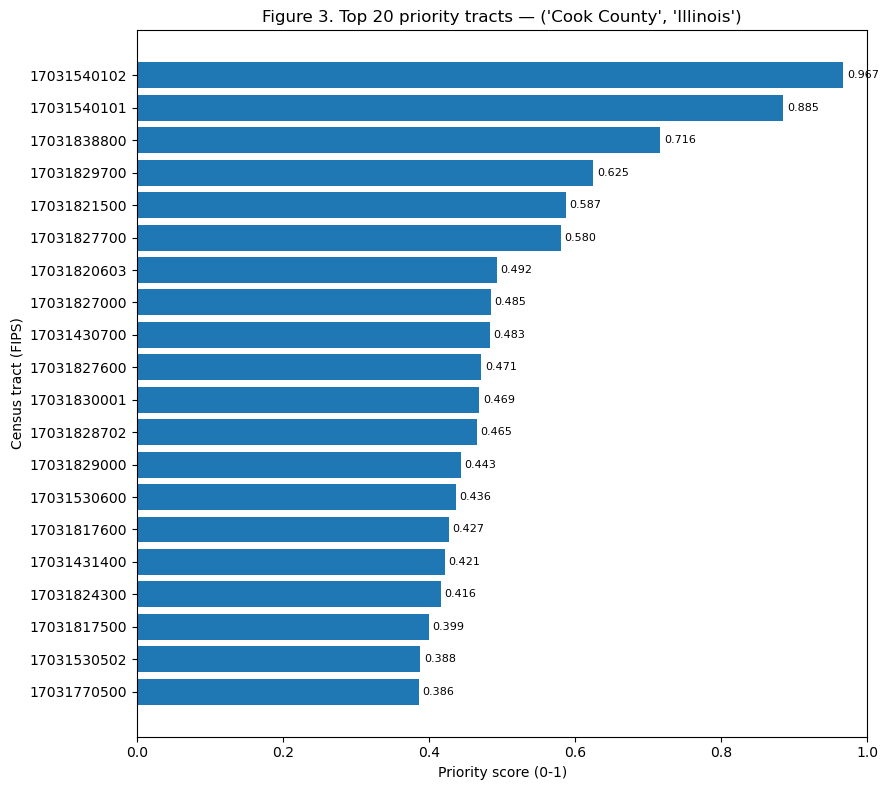

Highest-priority tract: 17031540102 | score 0.967


In [6]:
# Sort the tracts from highest to lowest priority score and select the top 20.
top20 = df.sort_values("PriorityScore", ascending=False).head(20)

# Create a horizontal bar chart showing the selected tracts.
fig, ax = plt.subplots(figsize=(9, 8))
ax.barh(top20["CensusTract"], top20["PriorityScore"])

# Place the highest-priority tract at the top of the chart.
ax.invert_yaxis()

# Label the axes and add a chart title.
ax.set_xlabel(LABELS["PriorityScore"])
ax.set_ylabel("Census tract (FIPS)")
ax.set_title(f"Figure 3. Top 20 priority tracts — {AREA_LABEL}")

# Display each tract's priority score next to its bar.
for y, (tract, score) in enumerate(zip(top20["CensusTract"], top20["PriorityScore"])):
    ax.text(score + 0.005, y, f"{score:.3f}", va="center", fontsize=8)

# Set the horizontal axis limit so the bars and labels fit within the chart.
ax.set_xlim(0, min(1.0, top20["PriorityScore"].max() + 0.08))

# Adjust the layout, save the chart, and display it.
fig.tight_layout()
fig.savefig(FIG_DIR / "fig3_top20.png", bbox_inches="tight")
plt.show()

# Print the census tract with the highest priority score.
print("Highest-priority tract:", top20.iloc[0]["CensusTract"],
      "| score", round(top20.iloc[0]["PriorityScore"], 3))

## Figure 5 — What drives each top tract's score (transparency)
Why: this is the acceptance-criteria #4 figure. Each top-15 tract's score is broken into its six normalized components, so a reviewer sees whether a tract ranks high because of poverty, distance, vehicle access, SNAP, or low income.

Uses the `_score` columns from the pipeline. 

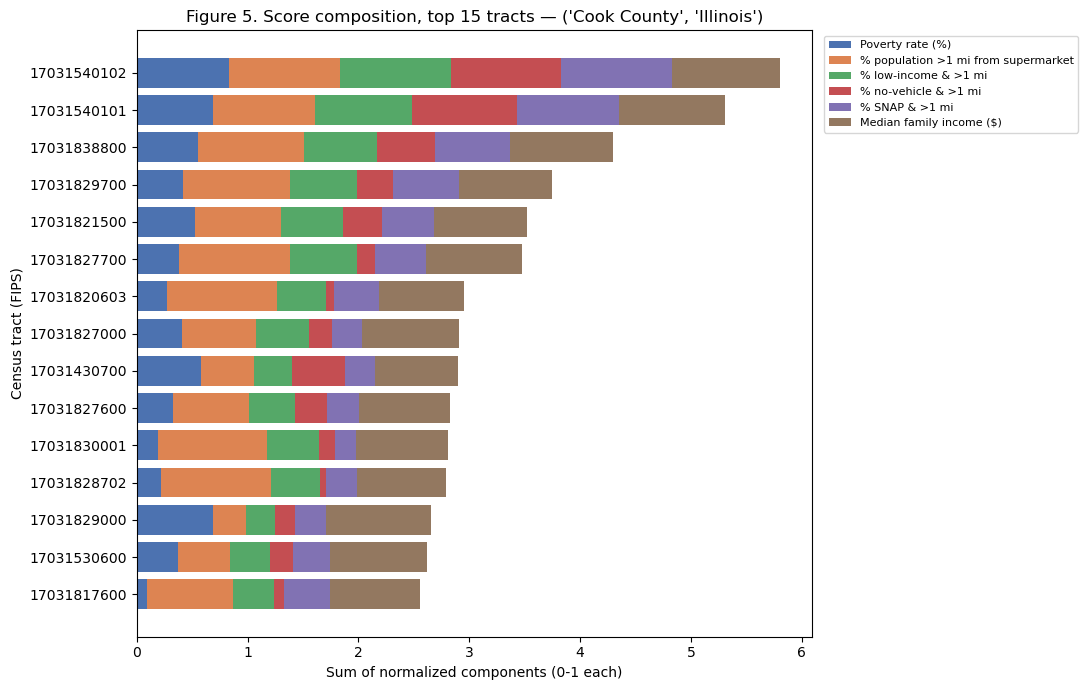

Note: bar length = sum of the six normalized parts; the final PriorityScore is their average.


In [7]:
# Create the column names for the six normalized indicators.
norm_cols = [v + "_score" for v in INDEX_VARS]

# Select the 15 tracts with the highest priority scores.
topN = df.sort_values("PriorityScore", ascending=False).head(15)

# Keep only the normalized components for these tracts.
comp = topN[norm_cols].copy()

# Use the original indicator names for the chart legend.
comp.columns = INDEX_VARS

# Set up the chart and the starting position for the stacked bars.
fig, ax = plt.subplots(figsize=(11, 7))
bottom = np.zeros(len(topN))

# Assign a different color to each indicator.
colors = ["#4C72B0", "#DD8452", "#55A868", "#C44E52", "#8172B3", "#937860"]

# Add each normalized indicator to the horizontal stacked bars.
for v, c in zip(INDEX_VARS, colors):
    vals = comp[v].values

    # Start each new section where the previous section ends.
    ax.barh(topN["CensusTract"], vals, left=bottom, label=LABELS.get(v, v), color=c)
    bottom += vals

# Put the highest-priority tract at the top.
ax.invert_yaxis()

# Label the axes and add the chart title.
ax.set_xlabel("Sum of normalized components (0-1 each)")
ax.set_ylabel("Census tract (FIPS)")
ax.set_title(f"Figure 5. Score composition, top 15 tracts — {AREA_LABEL}")

# Place the legend outside the chart to keep the bars easy to read.
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8)

# Save and display the chart.
fig.tight_layout()
fig.savefig(FIG_DIR / "fig5_composition.png", bbox_inches="tight")
plt.show()

# Explain how the component totals relate to the final priority score.
print("Note: bar length = sum of the six normalized parts; the final PriorityScore is their average.")

## Figure 6 — Correlation among the indicators (overlap / double-counting)
Why: the report flags that the four distance shares describe overlapping populations. Strong correlation among `la*1share` justifies the double-counting caveat and the choice to weight them modestly.

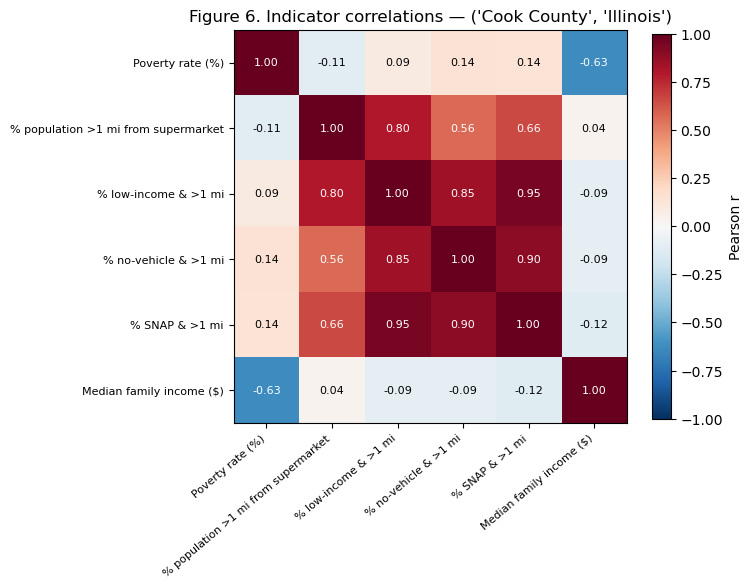

Strongest correlations:
  lalowi1share <-> lasnap1share: r = 0.95
  lahunv1share <-> lasnap1share: r = 0.90
  lalowi1share <-> lahunv1share: r = 0.85
  lapop1share <-> lalowi1share: r = 0.80


In [8]:
# Values closer to 1 or -1 show stronger relationships.
corr = df[INDEX_VARS].corr()

# Create the heatmap using colors to represent the correlation values.
fig, ax = plt.subplots(figsize=(7.5, 6.5))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)

# Add indicator names to both axes.
ax.set_xticks(range(len(INDEX_VARS))); ax.set_yticks(range(len(INDEX_VARS)))
ax.set_xticklabels([LABELS.get(v, v) for v in INDEX_VARS], rotation=40, ha="right", fontsize=8)
ax.set_yticklabels([LABELS.get(v, v) for v in INDEX_VARS], fontsize=8)

# Display the correlation value in each square.
for i in range(len(INDEX_VARS)):
    for j in range(len(INDEX_VARS)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center",
                color="white" if abs(corr.iloc[i, j]) > 0.5 else "black", fontsize=8)

# Add a color scale to explain the meaning of the colors.
fig.colorbar(im, ax=ax, shrink=0.8, label="Pearson r")
ax.set_title(f"Figure 6. Indicator correlations — {AREA_LABEL}")

# Save and display the heatmap.
fig.tight_layout()
fig.savefig(FIG_DIR / "fig6_correlation.png", bbox_inches="tight")
plt.show()

# Create a list of all unique pairs of indicators and their correlations.
pairs = [(INDEX_VARS[i], INDEX_VARS[j], corr.iloc[i, j])
         for i in range(len(INDEX_VARS)) for j in range(i+1, len(INDEX_VARS))]

# Sort the pairs by the absolute strength of their correlation.
pairs.sort(key=lambda t: abs(t[2]), reverse=True)

# Print the four strongest relationships for easier interpretation.
print("Strongest correlations:")
for a, b, r in pairs[:4]:
    print(f"  {a} <-> {b}: r = {r:.2f}")

## Figure 7 — Poverty vs. income, sized by population and colored by priority
Why: high-priority tracts should sit in the high-poverty / low-income corner. Point size = population (so a reviewer sees how many people each tract represents).

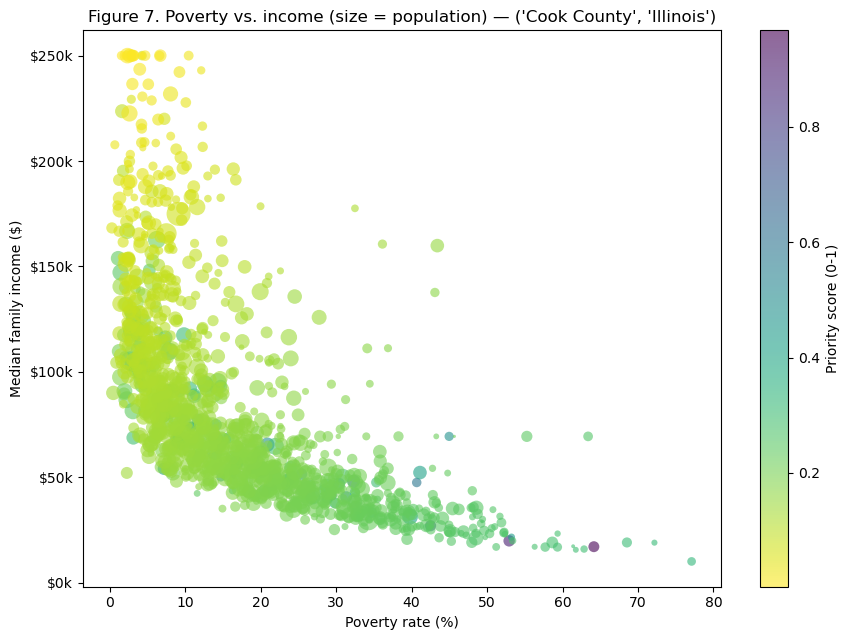

Expect: darker (higher-priority) points cluster in the high-poverty / low-income region.


In [9]:
# If population is unavailable, assign every tract a default size.
pop = df["Pop2010"] if "Pop2010" in df.columns else pd.Series(50, index=df.index)

# Create a scatter plot comparing poverty and median family income.
fig, ax = plt.subplots(figsize=(9, 6.5))
sc = ax.scatter(df["PovertyRate"], df["MedianFamilyIncome"],
                s=np.clip(pop/50, 5, 300), c=df["PriorityScore"],
                cmap="viridis_r", alpha=0.6, edgecolor="none")

# Label the axes and display income in thousands of dollars.
ax.set_xlabel(LABELS["PovertyRate"])
ax.set_ylabel(LABELS["MedianFamilyIncome"])
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"${x/1000:.0f}k"))

# Add the chart title and a color scale for priority scores.
ax.set_title(f"Figure 7. Poverty vs. income (size = population) — {AREA_LABEL}")
fig.colorbar(sc, ax=ax, label=LABELS["PriorityScore"])

# Save and display the chart.
fig.tight_layout()
fig.savefig(FIG_DIR / "fig7_poverty_income.png", bbox_inches="tight")
plt.show()

# Print a reminder of the expected relationship between the variables.
print("Expect: darker (higher-priority) points cluster in the high-poverty / low-income region.")

## Figure 9 *(optional)* — Choropleth map of PriorityScore

In [10]:
# ── Cell 10: Figure 9 (optional) — choropleth, requires a boundary file ────
GEO_PATH = None  # e.g. "shapefiles/cb_2019_17_tract_500k.shp"  (Illinois tracts)

if GEO_PATH:
    try:
        import geopandas as gpd
        gdf = gpd.read_file(GEO_PATH)
        gdf["GEOID"] = gdf["GEOID"].astype(str).str.zfill(11)
        # Keep Cook County tracts (county FIPS 031 within state 17 -> prefix "17031").
        gdf = gdf[gdf["GEOID"].str.startswith("17031")]
        merged = gdf.merge(df[["CensusTract", "PriorityScore"]],
                           left_on="GEOID", right_on="CensusTract", how="left")
        fig, ax = plt.subplots(figsize=(9, 9))
        merged.plot(column="PriorityScore", cmap="viridis_r", linewidth=0.1,
                    edgecolor="grey", legend=True, ax=ax,
                    legend_kwds={"label": "Priority score (0-1)"},
                    missing_kwds={"color": "lightgrey", "label": "No data"})
        ax.set_title(f"Figure 9. Priority score by census tract — {AREA_LABEL}")
        ax.axis("off")
        fig.savefig(FIG_DIR / "fig9_choropleth.png", bbox_inches="tight", dpi=150)
        plt.show()
        print(f"Mapped {merged['PriorityScore'].notna().sum()} tracts.")
    except ImportError:
        print("geopandas not installed. Run: pip install geopandas, then re-run this cell.")
    except Exception as e:
        print(f"Could not build the map: {e}")
else:
    print("Choropleth skipped — set GEO_PATH to a Cook County tract boundary file to enable it.")
    print("See the markdown above for the exact file to download (Illinois tracts, FIPS 17).")

Choropleth skipped — set GEO_PATH to a Cook County tract boundary file to enable it.
See the markdown above for the exact file to download (Illinois tracts, FIPS 17).
